# Brasaland Monthly Revenue Forecast

Target: `revenue_usd`. Source: `data/raw/sales/brasaland_sales.csv`
(120 monthly rows, 2016-01 through 2025-12, single `market` value
`"consolidated"`). Algorithm, feature, and metric choices are documented
in `README.md`; this notebook runs the same pipeline modules end to end
and inspects the results.

In [1]:
import _pathsetup  # noqa: F401
from data_prep import load_sales_data
from features import FEATURE_COLUMNS, TARGET_COLUMN, build_features, drop_rows_without_full_history
from train import chronological_split, run_training
from evaluate import evaluate_model
from forecast import forecast_next_n_months
from metrics import compute_all_metrics
import visualize as viz

import matplotlib.pyplot as plt
%matplotlib inline

## 1. Data preparation

In [2]:
raw = load_sales_data()
print(f"{len(raw)} rows, {raw['month'].min().date()} .. {raw['month'].max().date()}")
raw.head()

[data_prep] Note: `market` has a single constant value ('consolidated') across all 120 rows — it carries no discriminative information for this dataset and is not used as a feature.
120 rows, 2016-01-01 .. 2025-12-01


,month,revenue_usd,covers_served,avg_ticket_usd,market
0,2016-01-01,420817.20,37946,11.09,consolidated
1,2016-02-01,488751.47,42611,11.47,consolidated
2,2016-03-01,511823.56,41477,12.34,consolidated
3,2016-04-01,519608.98,46352,11.21,consolidated
4,2016-05-01,496096.09,44693,11.10,consolidated


In [3]:
raw.describe()

,month,revenue_usd,covers_served,avg_ticket_usd
count,120,120.00000,120.000000,120.000000
mean,2020-12-15 18:00:00,638707.64650,53375.158333,11.974000
min,2016-01-01 00:00:00,420817.20000,37645.000000,11.050000
25%,2018-06-23 12:00:00,553349.00000,46336.750000,11.485000
50%,2020-12-16 12:00:00,626518.51500,52166.000000,12.025000
75%,2023-06-08 12:00:00,722434.37000,59441.000000,12.390000
max,2025-12-01 00:00:00,994075.53000,81282.000000,12.950000
std,NaN,107889.06866,8912.183484,0.546154


No missing values, no duplicate months, no gap in the monthly sequence
(`load_sales_data` raises if any of those hold) — this dataset is clean.
`market` is constant (`"consolidated"`) across all 120 rows, so it carries
no information and is not used as a feature.

## 2. Feature engineering

In [4]:
featured = build_features(raw)
clean = drop_rows_without_full_history(featured)
print(f"{len(raw)} raw rows -> {len(clean)} usable rows (first 12 months dropped: need a full lag_12)")
clean[["month", *FEATURE_COLUMNS, TARGET_COLUMN]].head()

120 raw rows -> 108 usable rows (first 12 months dropped: need a full lag_12)


,month,month_of_year,year,quarter,month_sin,month_cos,lag_1,lag_12,roll_mean_3,roll_mean_6,revenue_usd
0,2017-01-01,1,2017,1,0.500000,8.660254e-01,617012.53,420817.20,549258.336667,519603.010000,440073.46
1,2017-02-01,2,2017,1,0.866025,5.000000e-01,440073.46,488751.47,524125.650000,513560.786667,513211.90
2,2017-03-01,3,2017,1,1.000000,6.123234e-17,513211.90,511823.56,523432.630000,514513.733333,553590.95
3,2017-04-01,4,2017,2,0.866025,-5.000000e-01,553590.95,519608.98,502292.103333,525775.220000,551431.36
4,2017-05-01,5,2017,2,0.500000,-8.660254e-01,551431.36,496096.09,539411.403333,531768.526667,536938.20


`covers_served` and `avg_ticket_usd` are intentionally excluded: both are
only known for the month being predicted, and `revenue_usd ≈ covers_served
× avg_ticket_usd` almost exactly in this dataset — using either as a
feature would leak the answer. Only calendar features (month/year/quarter,
cyclical sin/cos encoding) and the target's own lagged/rolling history are
used. No feature scaling is applied — RandomForestRegressor splits on raw
per-feature thresholds, so it's invariant to monotonic rescaling.

## 3. Chronological split

In [5]:
train_df, test_df = chronological_split(clean)
print(f"Train: {len(train_df)} rows ({train_df['month'].min().date()} .. {train_df['month'].max().date()})")
print(f"Test:  {len(test_df)} rows ({test_df['month'].min().date()} .. {test_df['month'].max().date()})")

Train: 84 rows (2017-01-01 .. 2023-12-01)
Test:  24 rows (2024-01-01 .. 2025-12-01)


Note: the requested "train 2016-2023 / test 2024-2025" describes the raw
calendar range. The first 12 *raw* months (2016) are already dropped for
lacking a full `lag_12`, so the usable train window is 2017-2023 (84 rows)
and test is 2024-2025 (24 rows).

## 4. Model training (RandomForestRegressor + TimeSeriesSplit tuning)

In [6]:
trained = run_training()
model, best_params = trained["model"], trained["best_params"]
print("Best hyperparameters (TimeSeriesSplit CV, neg MAE scoring):", best_params)

[data_prep] Note: `market` has a single constant value ('consolidated') across all 120 rows — it carries no discriminative information for this dataset and is not used as a feature.


Best hyperparameters (TimeSeriesSplit CV, neg MAE scoring): {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 400}


**Why RandomForestRegressor**: the dataset is small (108 usable rows) —
a model with many hyperparameters would be more likely to overfit than to
add value. Revenue growth + seasonality are nonlinear in the engineered
calendar/lag features; trees capture that without manual interaction
terms. `feature_importances_` gives free explainability. It needs little
tuning to get a reasonable result, which matters given this task's limited
time budget and this dataset's limited ability to support an expensive
search.

Hyperparameters were tuned via `GridSearchCV` with `TimeSeriesSplit`
(4 folds) over `n_estimators`, `max_depth`, `min_samples_leaf` — every
fold's validation block is strictly later in time than its training
block, and the test set was never touched during tuning.

## 5. Evaluation on the held-out test set (one-month-ahead)

In [7]:
results = evaluate_model(model, train_df, test_df)
results["model_metrics"]

{'mse': 3278949966.4012256,
 'rmse': 57262.116328347714,
 'mae': 45875.493224830534,
 'r2': 0.3975516455002319,
 'wape': 0.05944982262328735,
 'gini_regression': 0.731844608350206,
 'psi_predicted_distribution_train_vs_test': 10.921170785129723}

In [8]:
results["baseline_metrics"]

{'mse': 1966073072.3095543,
 'rmse': 44340.42255447679,
 'mae': 37575.68208333334,
 'r2': 0.6387692708409386,
 'wape': 0.04869413880424728,
 'gini_regression': 0.7374447729142168}

### Metric definitions and limitations

- **MSE/RMSE**: squared-error based — penalize large misses heavily,
  in USD² / USD. Sensitive to outliers; alone they say nothing about
  *directional bias* (consistently under- or over-forecasting).
- **MAE**: average absolute USD error. More robust to outliers than
  RMSE, but treats a $10k miss on a $400k month the same as on a $900k
  month.
- **R²**: fraction of test-set revenue variance explained relative to
  predicting the test-set mean. Can be negative if the model is worse
  than that trivial mean-predictor; here it should be compared against
  the *seasonal-naive* baseline instead of 0, since revenue has a strong
  trend the mean-predictor ignores entirely.
- **WAPE**: `sum(|error|) / sum(|actual|)` — a scale-free error rate,
  robust to any single month unlike MAPE (no near-zero actual here, but
  WAPE is the safer general choice).
- **Gini (regression, normalized ranking)**: NOT the classification Gini
  (`2*AUC-1`). This is the ranking/discrimination metric popularized in
  insurance-claims and Kaggle regression competitions: how well
  predictions *order* months relative to the best possible ordering
  (sorting by actual value), via the Lorenz curve. A model can rank months
  correctly (high Gini) while still being numerically off on each one
  (high MAE) — it answers a different question than the error metrics
  above, not a better one.
- **PSI (predicted-distribution drift)**: PSI is originally a
  classification/credit-scoring metric comparing a score's distribution
  across two populations; there's no single accepted regression
  adaptation. This notebook defines it explicitly: train-period
  predictions binned into deciles vs. test-period predictions compared
  against those same bins. It flags *distributional drift*, not accuracy.
- **K2 Score**: NOT computed. It isn't a recognized ML metric, and no
  document in this repo defines it — flagged as an open ambiguity per the
  task's own instruction, rather than guessing a formula. R² is reported
  separately under its own name.

**A low MSE alone is not enough**: a model that always predicts last
year's same month (the seasonal-naive baseline below) can have a low MSE
on a strongly seasonal series purely by exploiting the pattern, without
showing any real skill at the *change* from last year. Comparing against
that baseline, and looking at WAPE/Gini/the error-over-time plot together,
is what actually tells you whether the model earns its complexity.

## 6. Model vs. seasonal-naive baseline — and why the baseline wins here

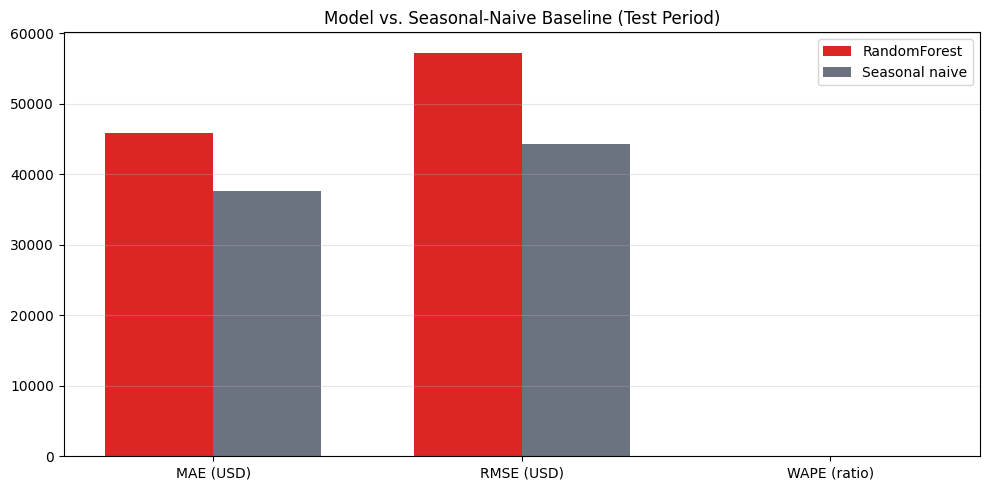

In [9]:
fig = viz.plot_model_vs_baseline(results["model_metrics"], results["baseline_metrics"])
plt.show()

**Finding, stated plainly: the seasonal-naive baseline outperforms the
RandomForestRegressor on every error metric in this test period**
(lower MAE/RMSE/WAPE, higher R²). Verified root cause — not a tuning
artifact:

In [10]:
import numpy as np
print("Train max revenue:      $%.2f" % train_df[TARGET_COLUMN].max())
print("Test actual range:      $%.2f .. $%.2f" % (test_df[TARGET_COLUMN].min(), test_df[TARGET_COLUMN].max()))
print("Model prediction range: $%.2f .. $%.2f" % (results["test_predictions"].min(), results["test_predictions"].max()))

Train max revenue:      $889619.26
Test actual range:      $638081.20 .. $994075.53
Model prediction range: $686184.96 .. $856275.85


Brasaland's revenue has a strong, steady upward trend. Tree-based models
(including Random Forest) **cannot extrapolate beyond the target range
seen during training** — every leaf predicts an average of training
labels that fell into it, so the maximum possible prediction is bounded
by (and in practice below) the training set's maximum. Since every test
month's actual revenue exceeds the training maximum, the model
systematically underpredicts throughout 2024-2025. The seasonal-naive
baseline (`lag_12`) has no such ceiling — it directly reuses a real prior
value from a point already past that ceiling, implicitly riding the trend.

This is a genuine, documented limitation of this algorithm choice for a
trending series, not a bug to silently fix by retuning. Reported here
rather than hidden, per the task's own request to document limitations.

## 7. Visualizations

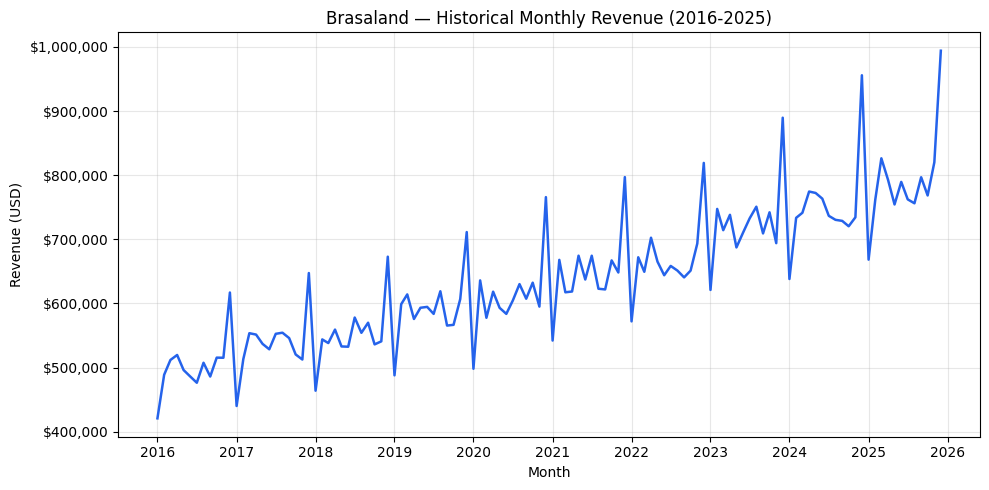

In [11]:
fig = viz.plot_historical_revenue(raw)
plt.show()

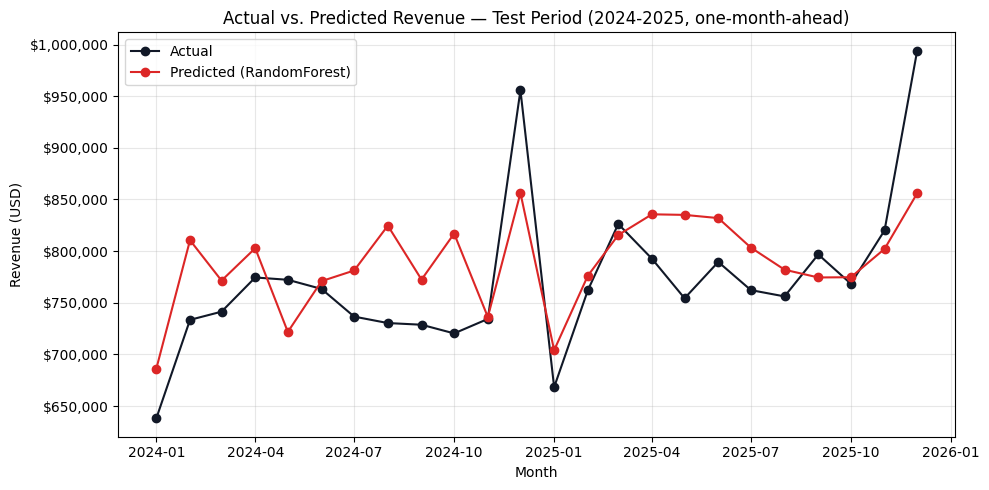

In [12]:
fig = viz.plot_actual_vs_predicted(test_df, results["test_predictions"])
plt.show()

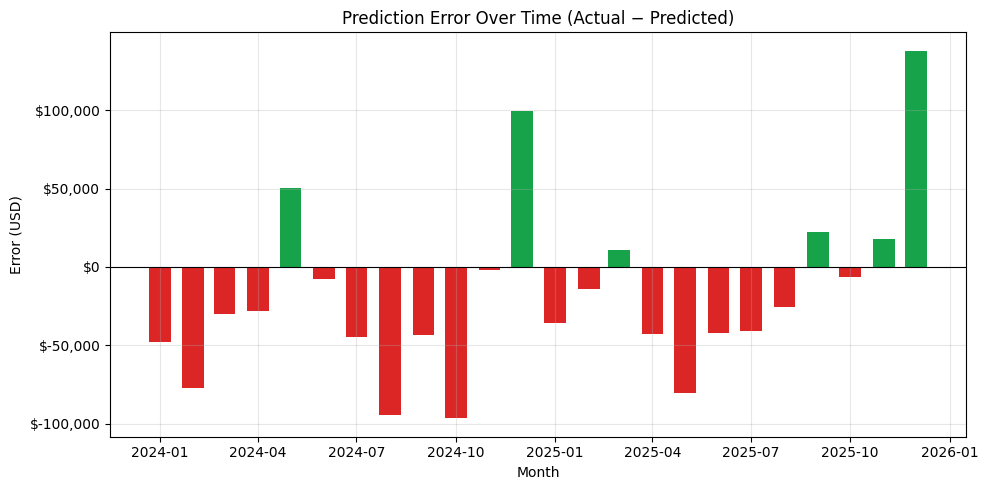

In [13]:
fig = viz.plot_prediction_errors(test_df, results["test_predictions"])
plt.show()

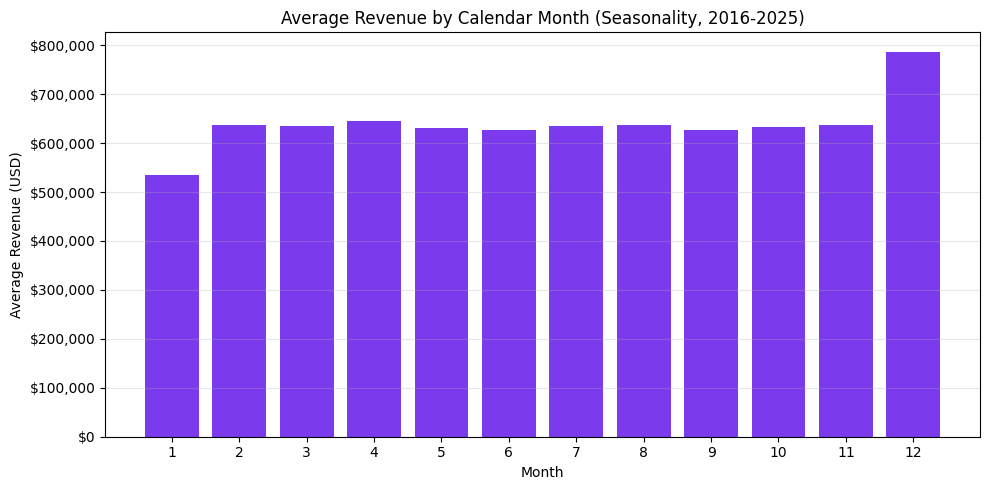

In [14]:
fig = viz.plot_seasonality(raw)
plt.show()

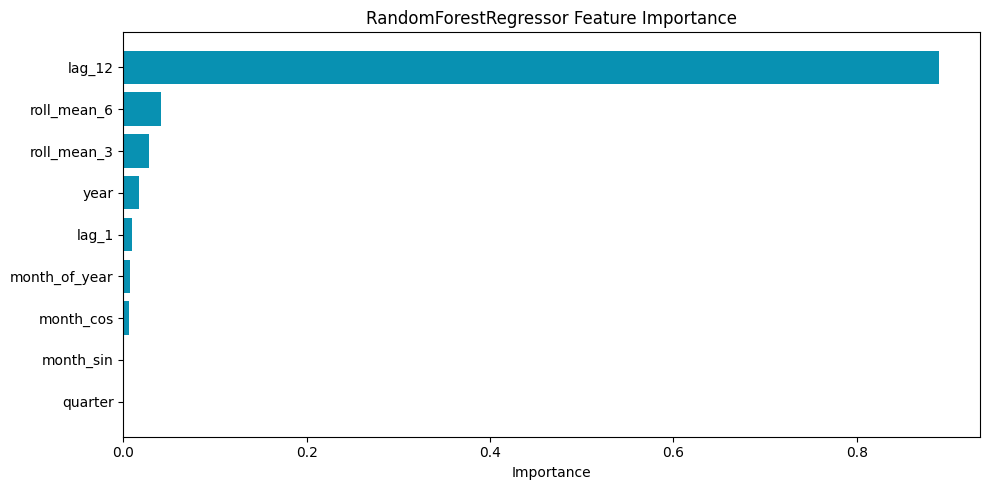

In [15]:
fig = viz.plot_feature_importance(model, FEATURE_COLUMNS)
plt.show()

## 8. 12-month recursive forecast

Distinct from section 5's evaluation: that was **one-month-ahead** (every
test row's lag/rolling features come from *real* historical revenue).
Below, each forecasted month's lag/rolling features are built from the
model's **own previous predictions**, recursively, since no real future
revenue exists yet. Errors can compound month over month — a materially
harder regime, never to be reported as the same kind of accuracy as
section 5.

In [16]:
forecast_df = forecast_next_n_months(model, raw, n_months=12)
forecast_df

,month,revenue_usd
0,2026-01-01,722199.531888
1,2026-02-01,832289.771315
2,2026-03-01,845444.737978
3,2026-04-01,838621.310923
4,2026-05-01,828951.687502
5,2026-06-01,835773.333822
6,2026-07-01,832090.168303
7,2026-08-01,830178.592867
8,2026-09-01,839378.173019
9,2026-10-01,836635.012682


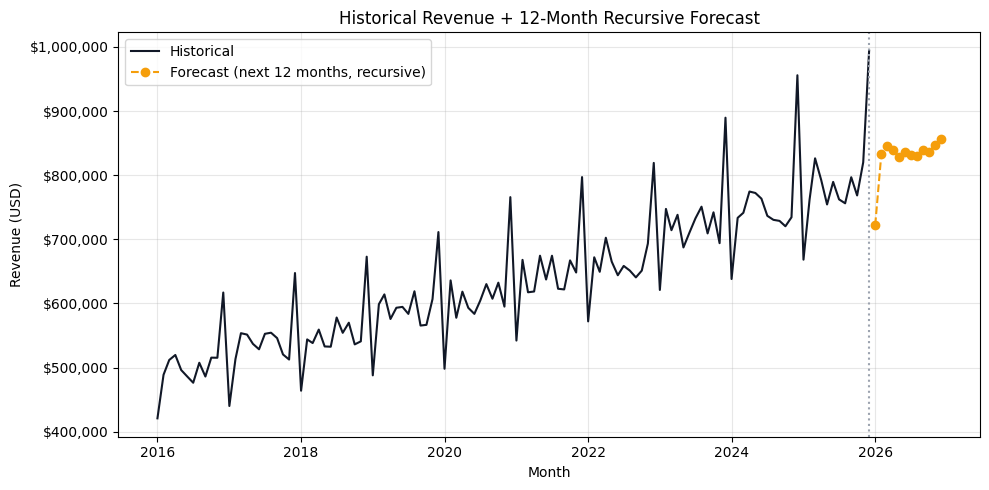

In [17]:
fig = viz.plot_forecast(raw, forecast_df)
plt.show()

Given section 6's finding, this 12-month forecast should be read with the
same caveat: because every forecasted month sits above the training
revenue ceiling, and each step recursively feeds off the previous
(already-underestimated) step, this forecast is **very likely a
conservative floor**, not a central estimate — it is bounded close to the
historical maximum rather than continuing the real trend. Confirmed by
`pipeline.py`'s run: the forecasted months stay in the ~$720k-856k range,
below the $994k already observed in December 2025.

## 9. Second model: predicting YoY growth instead of absolute revenue

Section 6 found that `RandomForestRegressor` underperforms the
seasonal-naive baseline because trees can't extrapolate past the training
revenue ceiling, and this series keeps growing past it. This section
tests a direct fix for that specific cause: instead of predicting
`revenue_usd` directly, predict the **year-over-year growth rate**
(`revenue_usd_t / revenue_usd_(t-12) - 1`), then reconstruct absolute
revenue as `revenue_usd_(t-12) * (1 + predicted_growth)`. The anchor
(`revenue_usd_(t-12)`) is always real, already-past-the-ceiling historical
data — so the reconstructed revenue is **not** bounded by the training
set's revenue range the way a direct revenue prediction is, even though
the *rate* being predicted stays within a modest, trend-independent band.

In [18]:
import _pathsetup  # noqa: F401
from features_growth import GROWTH_FEATURE_COLUMNS, GROWTH_TARGET_COLUMN, build_growth_features, drop_rows_without_full_growth_history, reconstruct_revenue
from train_growth import run_growth_training
from evaluate_growth import evaluate_growth_model, select_best_model

growth_featured = build_growth_features(raw)
growth_clean = drop_rows_without_full_growth_history(growth_featured)
print(f"{len(raw)} raw rows -> {len(growth_clean)} usable rows (first 24 months dropped: growth_lag_12 needs a growth rate from 12 months back, which itself needs revenue from 12 months before that)")
growth_clean[["month", *GROWTH_FEATURE_COLUMNS, GROWTH_TARGET_COLUMN]].head()

120 raw rows -> 96 usable rows (first 24 months dropped: growth_lag_12 needs a growth rate from 12 months back, which itself needs revenue from 12 months before that)


,month,month_of_year,year,quarter,month_sin,month_cos,lag_12,growth_lag_1,growth_lag_12,growth_roll_mean_3,growth_roll_mean_6,yoy_growth
0,2018-01-01,1,2018,1,0.500000,8.660254e-01,440073.46,0.049255,0.045759,0.017840,0.071553,0.054157
1,2018-02-01,2,2018,1,0.866025,5.000000e-01,513211.90,0.054157,0.050047,0.032677,0.053883,0.059789
2,2018-03-01,3,2018,1,1.000000,6.123234e-17,553590.95,0.059789,0.081605,0.054400,0.048459,-0.027785
3,2018-04-01,4,2018,2,0.866025,-5.000000e-01,551431.36,-0.027785,0.061243,0.028720,0.023280,0.014102
4,2018-05-01,5,2018,2,0.500000,-8.660254e-01,536938.20,0.014102,0.082327,0.015368,0.024023,-0.007468


**Leakage check**: every growth feature (`growth_lag_1`, `growth_lag_12`,
`growth_roll_mean_3`, `growth_roll_mean_6`) is shifted to only use growth
rates realized strictly before month `t` — verified in
`tests/test_features_growth.py::test_growth_features_only_see_the_past`.
`revenue_usd_t` itself (the value the target is derived from) never
appears as a feature, only as part of the target's own definition.

In [19]:
trained_growth = run_growth_training()
growth_model = trained_growth["model"]
train_df_growth, test_df_growth = trained_growth["train_df"], trained_growth["test_df"]
print(f"Train: {len(train_df_growth)} rows, test: {len(test_df_growth)} rows — same 24 test months as section 3 (2024-2025)")
print("Best hyperparameters:", trained_growth["best_params"])

[data_prep] Note: `market` has a single constant value ('consolidated') across all 120 rows — it carries no discriminative information for this dataset and is not used as a feature.


Train: 72 rows, test: 24 rows — same 24 test months as section 3 (2024-2025)
Best hyperparameters: {'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 400}


## 10. Growth model vs. original RandomForest vs. seasonal naive

In [20]:
growth_results = evaluate_growth_model(growth_model, train_df_growth, test_df_growth)
growth_results["revenue_metrics"]

{'mse': 754746405.2162962,
 'rmse': 27472.64831093457,
 'mae': 23735.907818281295,
 'r2': 0.8613288599867783,
 'wape': 0.030759244433273013,
 'gini_regression': 0.864448077819545,
 'psi_predicted_distribution_train_vs_test': 9.784398119506442}

In [21]:
best = select_best_model({
    "random_forest_revenue": results["model_metrics"],
    "random_forest_growth": growth_results["revenue_metrics"],
    "seasonal_naive": results["baseline_metrics"],
})
best

{'winner': 'random_forest_growth',
 'ranking': [{'model': 'random_forest_growth', 'mae': 23735.907818281295},
  {'model': 'seasonal_naive', 'mae': 37575.68208333334},
  {'model': 'random_forest_revenue', 'mae': 45875.493224830534}]}

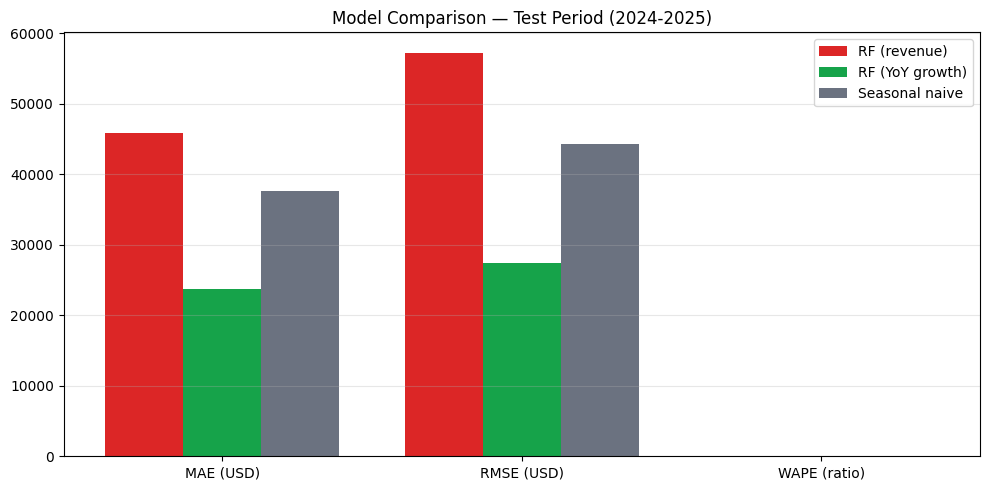

In [22]:
fig = viz.plot_three_way_comparison(results["model_metrics"], growth_results["revenue_metrics"], results["baseline_metrics"])
plt.show()

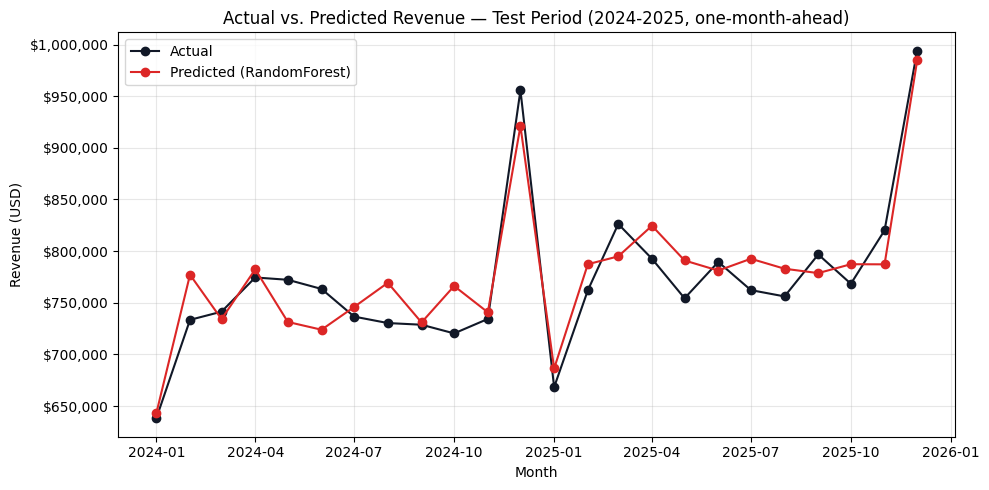

In [23]:
fig = viz.plot_actual_vs_predicted(test_df_growth, growth_results["test_predictions_revenue"])
plt.show()

**Result: the YoY-growth model wins.** It has the lowest MAE/RMSE/WAPE and
the highest R² and Gini of all three candidates — a clear improvement
over both the original absolute-revenue RandomForest *and* the
seasonal-naive baseline, not just over one of them. This confirms the
diagnosis in section 6: the problem was specifically the extrapolation
ceiling on an *absolute* revenue target, not RandomForestRegressor as an
algorithm — reframing the target to something that doesn't need to exceed
previously-seen values (a growth rate) while reconstructing through a
real, already-past-the-ceiling anchor resolves it directly.

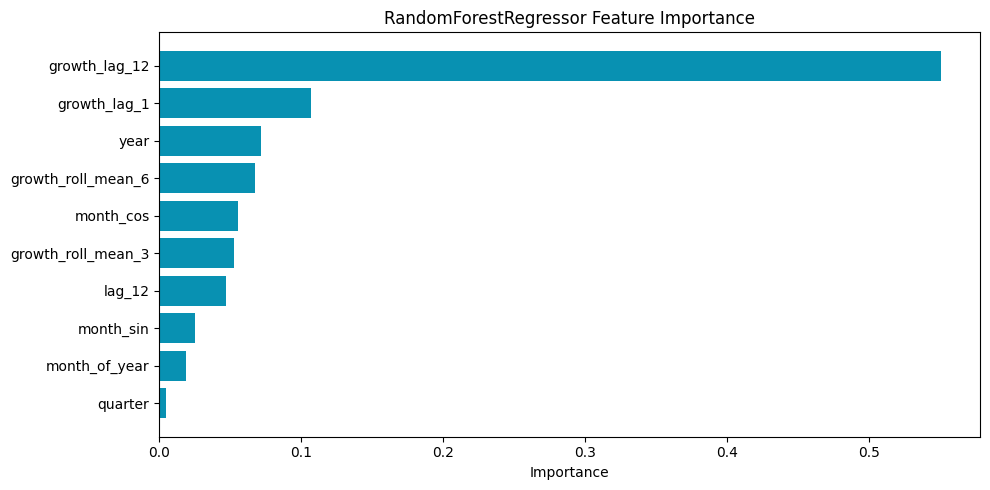

In [24]:
fig = viz.plot_feature_importance(growth_model, GROWTH_FEATURE_COLUMNS)
plt.show()

## 11. Final 12-month forecast, using the selected best model

Per section 10's result, the forecast below uses the **YoY-growth model**,
not the original absolute-revenue model from section 8 — `pipeline.py`
selects whichever model wins the comparison automatically, rather than
always defaulting to the first one built.

In [25]:
from pipeline import _forecast_with_growth_model

final_forecast_df = (
    _forecast_with_growth_model(growth_model, raw)
    if best["winner"] == "random_forest_growth"
    else forecast_next_n_months(model, raw, n_months=12)
)
final_forecast_df

,month,revenue_usd
0,2026-01-01,7.141616e+05
1,2026-02-01,8.226605e+05
2,2026-03-01,8.414803e+05
3,2026-04-01,8.554039e+05
4,2026-05-01,8.297085e+05
5,2026-06-01,8.589248e+05
6,2026-07-01,8.276872e+05
7,2026-08-01,8.202182e+05
8,2026-09-01,8.206112e+05
9,2026-10-01,8.093868e+05


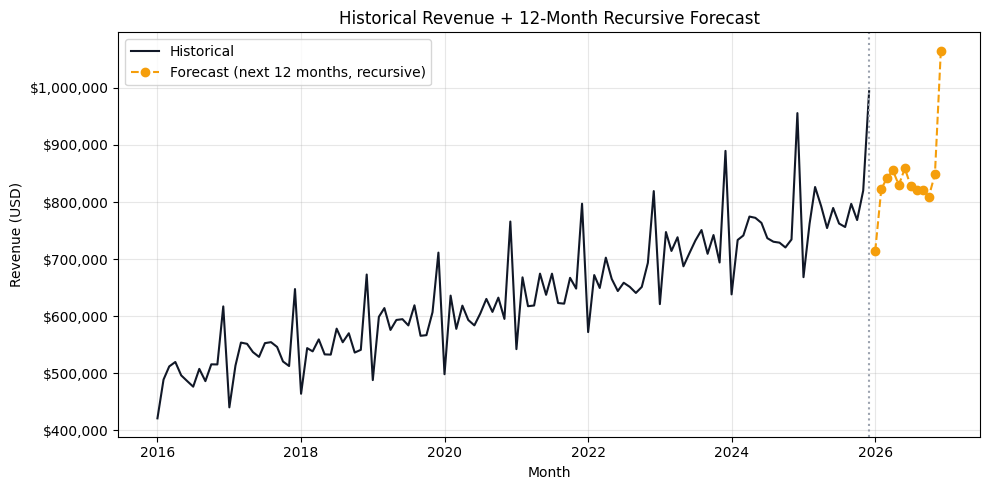

In [26]:
fig = viz.plot_forecast(raw, final_forecast_df)
plt.show()

Unlike section 8's forecast (bounded below the historical maximum), this
forecast is free to exceed the training-period revenue ceiling — December
2026 is forecast above $1M, past the $994k already observed in December
2025, consistent with the series' real trend rather than flattening
against it.

## 12. Conclusions and unresolved issues

- The dataset (`data/raw/sales/brasaland_sales.csv`) is clean, complete,
  and has no PII — safe as committed.
- Only `revenue_usd` exists; there is no cost/profit data in this repo
  today (see `data/pipelines/sales-profit-forecast/README.md`), so this
  pipeline forecasts **revenue**, not profit, despite the task's framing.
- The original absolute-revenue RandomForestRegressor underperforms the
  seasonal-naive baseline because of tree-based extrapolation limits on
  trending data — a verified limitation, not a tuning bug.
- **Reframing the target as YoY growth and reconstructing revenue through
  the real `lag_12` anchor fixes this**: it beats both the original model
  and the seasonal-naive baseline on every metric, and is the model
  `pipeline.py` now selects and forecasts with by default.
- `K2 Score` was not computed — no accepted definition exists anywhere in
  this repo. **Open issue**: needs a stakeholder definition before it can
  be added.
- `market` is constant (`"consolidated"`) in the current dataset — the
  pipeline would need no code change to generalize to multiple markets
  if/when that data exists, since neither feature module reads anything
  but `month`/`revenue_usd`.
- **Open issue**: the growth model's own forecast (section 11) is still a
  *recursive* multi-month forecast — compounding error month over month
  remains a real risk for the later months of the 12-month horizon, even
  though the single-step (one-month-ahead) evaluation in section 10 is
  strong. Not quantified further here (e.g. via a backtested multi-step
  recursive error) — a natural next step, not done due to time budget.